&nbsp;
# <div align=center><font color=green> <span style="background-color: #e6f7ff; padding: 2px; color: green; font-family: monospace;">Scikit-learn</span> : MLP, SVM</font></div>
<!-- # <div align=center> Part II </div> -->
<!-- ## <div align=center> & Ziping Zhao</div> -->

**<div align=center> School of Information Science and Technology </div>**
**<div align=center>ShanghaiTech University, Shanghai, China</div>**

**<div align=center><font size="7">CS182: Introduction to Machine Learning<font/></div>**
    
**<div align=center><font size="7">http://cs182.sist.shanghaitech.edu.cn<font/></div>**

### <div align=center><font color=green> Sec. 1.4, Sec. 1.17, Sec. 1.13 & Sec 1.2 of  <span style="background-color: #e6f7ff; padding: 2px; color: green; font-family: monospace;">Scikit-learn</span> </font></div>

## Learning Objectives

- Introduction to multi-layer perceptron (MLP) & implementing MLP in `scikit-learn`.

- Introduction to SVMs & implementing SVMs in `scikit-learn`.

- Introduction to Dimension reduction methods (feature selection, PCA， LDA) in `scikit-learn`.

# <div align=Left>Multi-layer perceptron (MLP) </div>
<br />

## Multi-layer Perceptron (MLP) in `sklearn.neural_network`

- `scikit-learn` offers no GPU support, thus the implementation is not intended for large-scale applications.
<br />

- If you want to acclerate the processing speed, you can combine `scikit-learn` with other GPU-based frameworks ([Related Projects](https://scikit-learn.org/stable/related_projects.html#related-projects))

## Multi-layer Perceptron
- A supervised learning algorithm that learns a function $f:\mathbb{R}^m \rightarrow \mathbb{R}^o$ by training on a dataset.

- Given a set of features and a target, it can learn a non-linear function approximator for either classification or regression.

- Between the input and output layer, there can be one or more non-linear hidden layers.

<!-- <figure style="text-align: center;">
    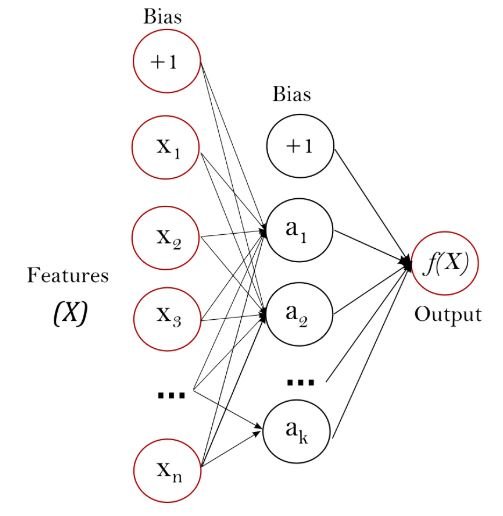
    <figcaption>One Hidden layer MLP</figcaption>
</figure> -->

## Advantages and disadvantages of multi-layer perceptron
- Advantages:
    + Capability to learn non-linear models
    + Capability to learn models in real-time (online learning) using `partial_fit`.

- Disadvantages:
    + MLP with hidden layers have a non-convex loss function where there exists more than one local minimum. Therefore different random weight initializations can lead to different validation accuracy.
    + MLP requires tuning a number of hyperparameters such as the number of hidden neurons, layers, and iterations.
    + MLP is sensitive to feature scaling.

## Classification `MLPClassifier`

- Class `MLPClassifier` implements a multi-layer perceptron (MLP) algorithm that trains using Backpropagation.

- Train on two arrays:
    + array $\mathbf{X}$: (n_samples, n_features)
    + array $y$: (n_samples,)

- `MLPClassifier` supports only the Cross-Entropy loss function., which in binary case is given as

$$\text{Loss}(\hat{\mathbf{y}}, \mathbf{y}, \mathbf{W}) = -\frac{1}{n}\sum_{i=0}^n(y_i\ln\hat{y}_i+(1-y_i)\ln(1-\hat{y_i})) + \frac{\alpha}{2n}\Vert \mathbf{W} \Vert_2^2$$

In [224]:
from sklearn.neural_network import MLPClassifier
?MLPClassifier

Init signature:
MLPClassifier(
    hidden_layer_sizes=(100,),
    activation='relu',
    *,
    solver='adam',
    alpha=0.0001,
    batch_size='auto',
    learning_rate='constant',
    learning_rate_init=0.001,
    power_t=0.5,
    max_iter=200,
    shuffle=True,
    random_state=None,
    tol=0.0001,
    verbose=False,
    warm_start=False,
    momentum=0.9,
    nesterovs_momentum=True,
    early_stopping=False,
    validation_fraction=0.1,
    beta_1=0.9,
    beta_2=0.999,
    epsilon=1e-08,
    n_iter_no_change=10,
    max_fun=15000,
)
Docstring:     
Multi-layer Perceptron classifier.

This model optimizes the log-loss function using LBFGS or stochastic
gradient descent.

.. versionadded:: 0.18

Parameters
----------
hidden_layer_sizes : array-like of shape(n_layers - 2,), default=(100,)
    The ith element represents the number of neurons in the ith
    hidden layer.

activation : {'identity', 'logistic', 'tanh', 'relu'}, default='relu'
    Activation function for the hidden laye

## How to use `MLPClassifier`?

In [225]:
# Train
from sklearn.neural_network import MLPClassifier
X = [[0., 0.], [1., 1.]]
y = [0, 1]
clf = MLPClassifier(solver='lbfgs', alpha=1e-5,
                    hidden_layer_sizes=(5, 2), random_state=1)
clf.fit(X, y)

MLPClassifier(alpha=1e-05, hidden_layer_sizes=(5, 2), random_state=1,
              solver='lbfgs')

In [226]:
# Predict
clf.predict([[2., 2.], [-1., -2.]])

array([1, 0])

In [227]:
# the weight matrices that constitute the model parameters
[coef.shape for coef in clf.coefs_]

[(2, 5), (5, 2), (2, 1)]

For classification, `MLPClassifier` minimizes the Cross-Entropy loss function, giving a vector of probability estimates $P(y|\mathbf{x})$ per sample $\mathbf{x}$

In [228]:
clf.predict_proba([[2., 2.], [1., 2.]])

array([[1.96718015e-04, 9.99803282e-01],
       [1.96718015e-04, 9.99803282e-01]])

- `MLPClassifier` supports multi-class classification by applying Softmax as the output function.

- `MLPClassifier` supports multi-label classification in which a sample can belong to more than one class.

    + Values larger or equal to $0.5$ are rounded to $1$, otherwise to $0$.

    + For a predicted output of a sample, the indices where the value is 1 represents the assigned classes of that sample

In [229]:
X = [[0., 0.], [1., 1.]]
y = [[0, 1], [1, 1]]
clf = MLPClassifier(solver='lbfgs', alpha=1e-5,
                    hidden_layer_sizes=(15,), random_state=1)
clf.fit(X, y)

MLPClassifier(alpha=1e-05, hidden_layer_sizes=(15,), random_state=1,
              solver='lbfgs')

In [230]:
clf.predict([[1., 2.]])

array([[1, 1]])

In [231]:
clf.predict([[0., 0.]])

array([[0, 1]])

## Case: Visualization of MLP weights on MNIST

In [232]:
import warnings

import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

In [335]:
# Load data from https://www.openml.org/d/554
X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
X = X / 255.0

# Split data into train partition and test partition
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0, test_size=0.7)

/Library/Python/3.9/site-packages/sklearn/datasets/_openml.py:1002: FutureWarning: The default value of `parser` will change from `'liac-arff'` to `'auto'` in 1.4. You can set `parser='auto'` to silence this warning. Therefore, an `ImportError` will be raised from 1.4 if the dataset is dense and pandas is not installed. Note that the pandas parser may return different data types. See the Notes Section in fetch_openml's API doc for details.
  warn(


In [342]:
mlp = MLPClassifier(
    hidden_layer_sizes=(40,),
    max_iter=8,
    alpha=1e-4,
    solver="sgd",
    verbose=10,
    random_state=1,
    learning_rate_init=0.2,
)

Iteration 1, loss = 0.44139186
Iteration 2, loss = 0.19174891
Iteration 3, loss = 0.13983521
Iteration 4, loss = 0.11378556
Iteration 5, loss = 0.09443967
Iteration 6, loss = 0.07846529
Iteration 7, loss = 0.06506307
Iteration 8, loss = 0.05534985
Training set score: 0.986429
Test set score: 0.953061


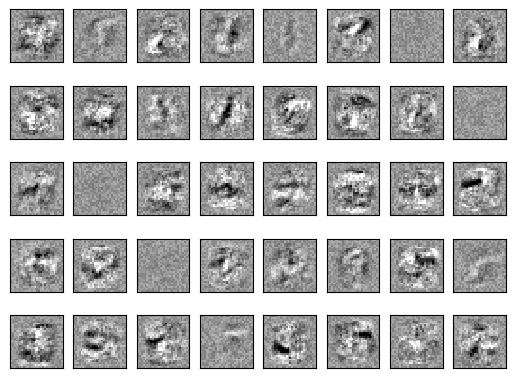

In [343]:
# this example won't converge because of resource usage constraints on
# our Continuous Integration infrastructure, so we catch the warning and
# ignore it here
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=ConvergenceWarning, module="sklearn")
    mlp.fit(X_train, y_train)

print("Training set score: %f" % mlp.score(X_train, y_train))
print("Test set score: %f" % mlp.score(X_test, y_test))

fig, axes = plt.subplots(5, 8)
# use global min / max to ensure all weights are shown on the same scale
vmin, vmax = mlp.coefs_[0].min(), mlp.coefs_[0].max()
for coef, ax in zip(mlp.coefs_[0].T, axes.ravel()):
    ax.matshow(coef.reshape(28, 28), cmap=plt.cm.gray, vmin=0.5 * vmin, vmax=0.5 * vmax)
    ax.set_xticks(())
    ax.set_yticks(())

plt.show()

## Regression `MLPRegressor`

- `MLPRegressor` implements a multi-layer perceptron (MLP) that trains using backpropagation with no activation function in the output layer.

- It uses the square error as the loss function, and the output is a set of continuous values.

$$\text{Loss}(\hat{\mathbf{y}}, \mathbf{y}, \mathbf{W}) = \frac{1}{2n}\sum_{i=0}^n\Vert \hat{y}_i - y_i \Vert_2^2 + \frac{\alpha}{2n}\Vert \mathbf{W} \Vert_2^2$$

- It supports multi-output regression, in which a sample can have more than one target.

In [236]:
from sklearn.neural_network import MLPRegressor
?MLPRegressor

Init signature:
MLPRegressor(
    hidden_layer_sizes=(100,),
    activation='relu',
    *,
    solver='adam',
    alpha=0.0001,
    batch_size='auto',
    learning_rate='constant',
    learning_rate_init=0.001,
    power_t=0.5,
    max_iter=200,
    shuffle=True,
    random_state=None,
    tol=0.0001,
    verbose=False,
    warm_start=False,
    momentum=0.9,
    nesterovs_momentum=True,
    early_stopping=False,
    validation_fraction=0.1,
    beta_1=0.9,
    beta_2=0.999,
    epsilon=1e-08,
    n_iter_no_change=10,
    max_fun=15000,
)
Docstring:     
Multi-layer Perceptron regressor.

This model optimizes the squared error using LBFGS or stochastic gradient
descent.

.. versionadded:: 0.18

Parameters
----------
hidden_layer_sizes : array-like of shape(n_layers - 2,), default=(100,)
    The ith element represents the number of neurons in the ith
    hidden layer.

activation : {'identity', 'logistic', 'tanh', 'relu'}, default='relu'
    Activation function for the hidden layer.

  

## How to use `MLPRegressor`： fit a sin function

In [237]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import numpy as np

In [238]:
# 1. Generate random data
def generate_data(n_samples=100):
    np.random.seed(42)
    X = np.random.rand(n_samples, 1) * 10  # Feature matrix (100, 1), values in [0, 10]
    y = np.sin(X).ravel() + np.random.normal(0, 0.1, n_samples)  # Target values with noise
    return X, y

X, y = generate_data()

# 2. Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [239]:
# 3. Initialize and train the MLPRegressor
mlp = MLPRegressor(hidden_layer_sizes=(128, 64, 32), activation='relu', solver='adam', 
                   max_iter=500, random_state=42)
mlp.fit(X_train, y_train)

# 4. Predict on the test set
y_pred = mlp.predict(X_test)

# 5. Compute the Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse:.4f}")


Mean Squared Error: 0.0138


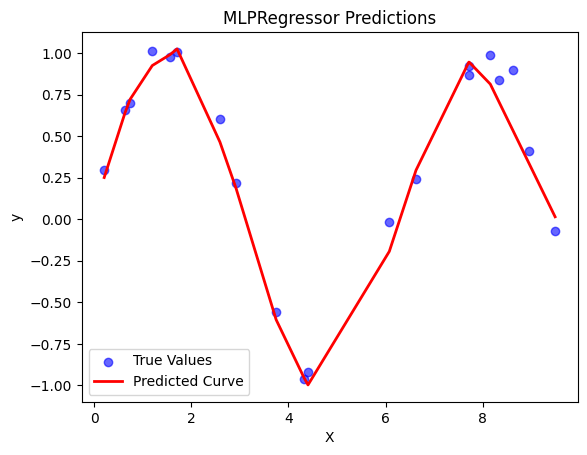

In [240]:
# 6. Visualize the results
import matplotlib.pyplot as plt

# Sort X_test to plot a smooth curve
sorted_indices = np.argsort(X_test.ravel())
X_test_sorted = X_test[sorted_indices]
y_test_sorted = y_test[sorted_indices]
y_pred_sorted = y_pred[sorted_indices]

plt.scatter(X_test, y_test, color='blue', label='True Values', alpha=0.6)
plt.plot(X_test_sorted, y_pred_sorted, color='red', label='Predicted Curve', linewidth=2)
plt.title('MLPRegressor Predictions')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.show()

## Some tips on pratical use

- MLP is sensitive to feature scaling, so it is highly recommmended to scale your data.
    + Scale each attribute on the input vector $\mathbf{X}$ to $[0,1]$ or $[-1,+1]$.
    + Standardlize it to have mean $0$ and variance $1$.
    + Apply the same scaling to the test set for meaningful results.
<br />

- Finding a reasonable regulaization parameter $\alpha$ is best done.

## Finding a reasonable regulaization parameter $\alpha$ is best done.

In [241]:
# Varying regularization in Multi-layer Perceptron
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import make_circles, make_classification, make_moons
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [242]:
h = 0.02  # step size in the mesh

alphas = np.logspace(-1, 1, 5)

classifiers = []
names = []
for alpha in alphas:
    classifiers.append(
        make_pipeline(
            StandardScaler(),
            MLPClassifier(
                solver="lbfgs",
                alpha=alpha,
                random_state=1,
                max_iter=2000,
                early_stopping=True,
                hidden_layer_sizes=[10, 10],
            ),
        )
    )
    names.append(f"alpha {alpha:.2f}")


In [243]:
# generate linear-separated dataset
X, y = make_classification(
    n_features=2, n_redundant=0, n_informative=2, random_state=0, n_clusters_per_class=1
) 
rng = np.random.RandomState(2)
X += 2 * rng.uniform(size=X.shape)
linearly_separable = (X, y)

datasets = [
    make_moons(noise=0.3, random_state=0),
    make_circles(noise=0.2, factor=0.5, random_state=1),
    linearly_separable,
]

figure = plt.figure(figsize=(17, 9))
i = 1

<Figure size 1700x900 with 0 Axes>

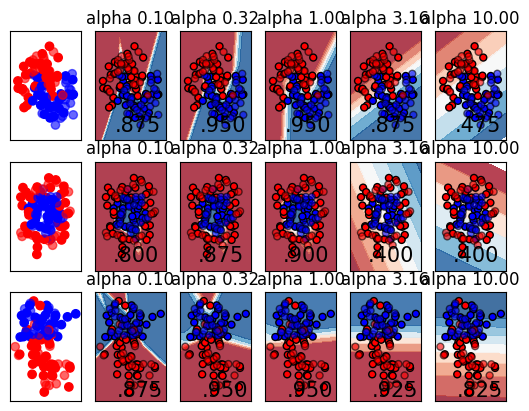

In [244]:
# iterate over datasets
for X, y in datasets:
    # split into training and test part
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.4, random_state=42
    )

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    # just plot the dataset first
    cm = plt.cm.RdBu
    cm_bright = ListedColormap(["#FF0000", "#0000FF"])
    ax = plt.subplot(len(datasets), len(classifiers) + 1, i)
    # Plot the training points
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_bright)
    # and testing points
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=cm_bright, alpha=0.6)
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.set_xticks(())
    ax.set_yticks(())
    i += 1

    # iterate over classifiers
    for name, clf in zip(names, classifiers):
        ax = plt.subplot(len(datasets), len(classifiers) + 1, i)
        clf.fit(X_train, y_train)
        score = clf.score(X_test, y_test)

        # Plot the decision boundary. For that, we will assign a color to each
        # point in the mesh [x_min, x_max] x [y_min, y_max].
        if hasattr(clf, "decision_function"):
            Z = clf.decision_function(np.column_stack([xx.ravel(), yy.ravel()]))
        else:
            Z = clf.predict_proba(np.column_stack([xx.ravel(), yy.ravel()]))[:, 1]

        # Put the result into a color plot
        Z = Z.reshape(xx.shape)
        ax.contourf(xx, yy, Z, cmap=cm, alpha=0.8)

        # Plot also the training points
        ax.scatter(
            X_train[:, 0],
            X_train[:, 1],
            c=y_train,
            cmap=cm_bright,
            edgecolors="black",
            s=25,
        )
        # and testing points
        ax.scatter(
            X_test[:, 0],
            X_test[:, 1],
            c=y_test,
            cmap=cm_bright,
            alpha=0.6,
            edgecolors="black",
            s=25,
        )

        ax.set_xlim(xx.min(), xx.max())
        ax.set_ylim(yy.min(), yy.max())
        ax.set_xticks(())
        ax.set_yticks(())
        ax.set_title(name)
        ax.text(
            xx.max() - 0.3,
            yy.min() + 0.3,
            f"{score:.3f}".lstrip("0"),
            size=15,
            horizontalalignment="right",
        )
        i += 1
figure.subplots_adjust(left=0.02, right=0.98)
plt.show()

## Some tips on pratical use
- Some Empirical phenomenon about the optimizers
    + **SGD** with momentum or nesterov's momentum, can perform better than above two algorithms if learning rate is correctly tuned.
    + **L-BFGS** converges faster and with better solutions on small data.
    + **Adam** is very robust for relatively large datasets.

In [344]:
import warnings

import matplotlib.pyplot as plt

from sklearn import datasets
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import MinMaxScaler

In [345]:
# different learning rate schedules and momentum parameters
params = [
    {
        "solver": "sgd",
        "learning_rate": "constant",
        "momentum": 0,
        "learning_rate_init": 0.2,
    },
    {
        "solver": "sgd",
        "learning_rate": "constant",
        "momentum": 0.9,
        "nesterovs_momentum": False,
        "learning_rate_init": 0.2,
    },
    {
        "solver": "sgd",
        "learning_rate": "constant",
        "momentum": 0.9,
        "nesterovs_momentum": True,
        "learning_rate_init": 0.2,
    },
    {
        "solver": "sgd",
        "learning_rate": "invscaling",
        "momentum": 0,
        "learning_rate_init": 0.2,
    },
    {
        "solver": "sgd",
        "learning_rate": "invscaling",
        "momentum": 0.9,
        "nesterovs_momentum": False,
        "learning_rate_init": 0.2,
    },
    {
        "solver": "sgd",
        "learning_rate": "invscaling",
        "momentum": 0.9,
        "nesterovs_momentum": True,
        "learning_rate_init": 0.2,
    },
    {"solver": "adam", "learning_rate_init": 0.01},
]

In [346]:
labels = [
    "constant learning-rate",
    "constant with momentum",
    "constant with Nesterov's momentum",
    "inv-scaling learning-rate",
    "inv-scaling with momentum",
    "inv-scaling with Nesterov's momentum",
    "adam",
]

plot_args = [
    {"c": "red", "linestyle": "-"},
    {"c": "green", "linestyle": "-"},
    {"c": "blue", "linestyle": "-"},
    {"c": "red", "linestyle": "--"},
    {"c": "green", "linestyle": "--"},
    {"c": "blue", "linestyle": "--"},
    {"c": "black", "linestyle": "-"},
]

In [347]:
def plot_on_dataset(X, y, ax, name):
    # for each dataset, plot learning for each learning strategy
    print("\nlearning on dataset %s" % name)
    ax.set_title(name)

    X = MinMaxScaler().fit_transform(X)
    mlps = []
    if name == "digits":
        # digits is larger but converges fairly quickly
        max_iter = 15
    else:
        max_iter = 400

    for label, param in zip(labels, params):
        print("training: %s" % label)
        mlp = MLPClassifier(random_state=0, max_iter=max_iter, **param)

        # some parameter combinations will not converge as can be seen on the
        # plots so they are ignored here
        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore", category=ConvergenceWarning, module="sklearn"
            )
            mlp.fit(X, y)

        mlps.append(mlp)
        print("Training set score: %f" % mlp.score(X, y))
        print("Training set loss: %f" % mlp.loss_)
    for mlp, label, args in zip(mlps, labels, plot_args):
        ax.plot(mlp.loss_curve_, label=label, **args)


learning on dataset iris
training: constant learning-rate
Training set score: 0.980000
Training set loss: 0.096950
training: constant with momentum
Training set score: 0.980000
Training set loss: 0.049530
training: constant with Nesterov's momentum
Training set score: 0.980000
Training set loss: 0.049540
training: inv-scaling learning-rate
Training set score: 0.360000
Training set loss: 0.978444
training: inv-scaling with momentum
Training set score: 0.860000
Training set loss: 0.504185
training: inv-scaling with Nesterov's momentum
Training set score: 0.860000
Training set loss: 0.503452
training: adam
Training set score: 0.980000
Training set loss: 0.045311

learning on dataset digits
training: constant learning-rate
Training set score: 0.956038
Training set loss: 0.243802
training: constant with momentum
Training set score: 0.992766
Training set loss: 0.041297
training: constant with Nesterov's momentum
Training set score: 0.993879
Training set loss: 0.042898
training: inv-scaling 

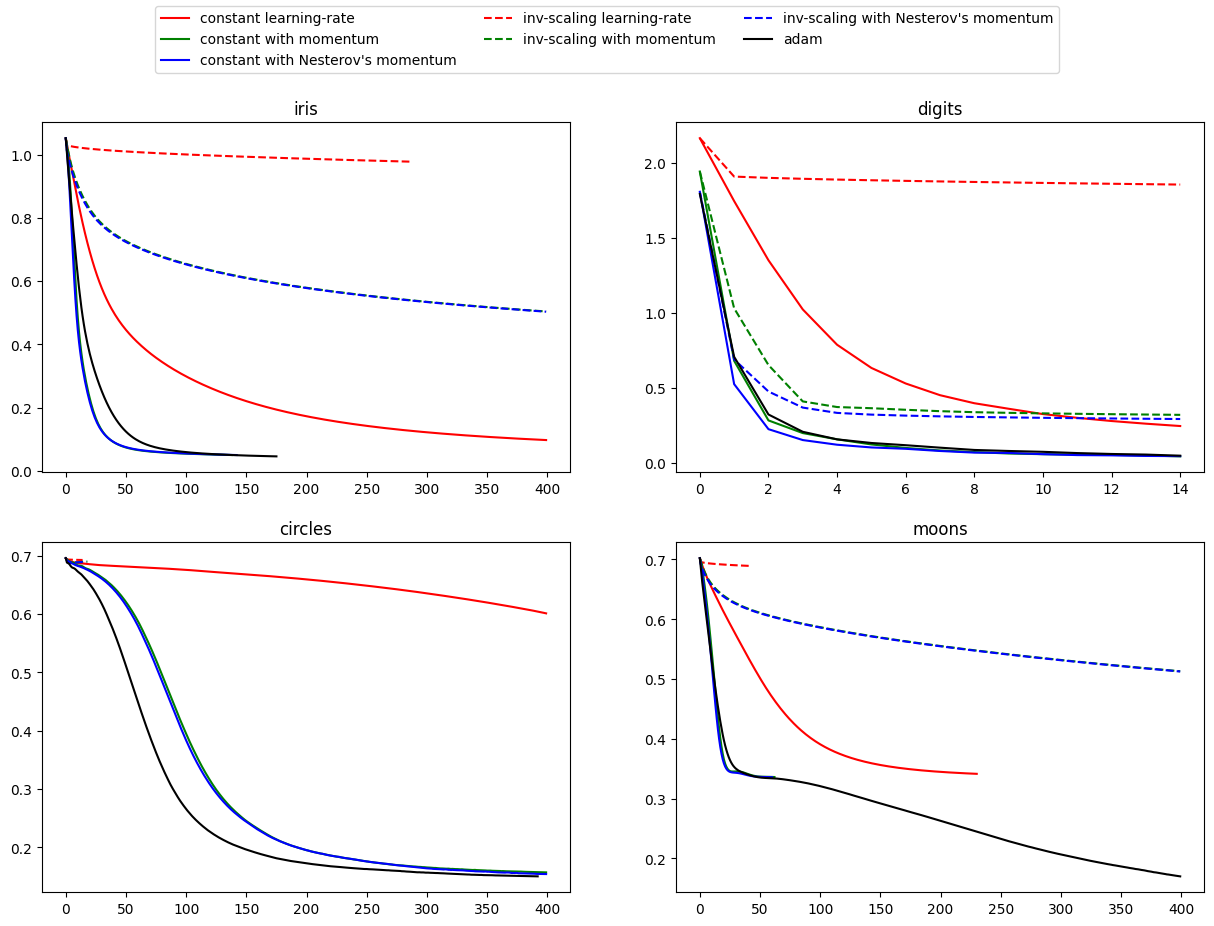

In [249]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
# load / generate some toy datasets
iris = datasets.load_iris()
X_digits, y_digits = datasets.load_digits(return_X_y=True)
data_sets = [
    (iris.data, iris.target),
    (X_digits, y_digits),
    datasets.make_circles(noise=0.2, factor=0.5, random_state=1),
    datasets.make_moons(noise=0.3, random_state=0),
]

for ax, data, name in zip(
    axes.ravel(), data_sets, ["iris", "digits", "circles", "moons"]
):
    plot_on_dataset(*data, ax=ax, name=name)

fig.legend(ax.get_lines(), labels, ncol=3, loc="upper center")
plt.show()

## Some tips on pratical use
- If you want more control over stopping criteria or learning rate in **SGD**, or want to do additional monitoring, using <font style=background:Grey color=DarkViolet>warm_start=Ture</font> and <font style=background:Grey color=DarkViolet>max_iter=1</font> and iterating yourself can be helpful.

In [250]:
from sklearn.neural_network import MLPClassifier
X = [[0., 0.], [1., 1.]]
y = [0, 1]
clf = MLPClassifier(hidden_layer_sizes=(15,), random_state=1, max_iter=1, warm_start=True)
for i in range(10):
    clf.fit(X, y)
    # additional monitoring / inspection

/Library/Python/3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/Library/Python/3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/Library/Python/3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/Library/Python/3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
/Library/Python/3.9/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochast

# Summary for `MLP`

- Classification (`MLPClassifier`)

- Regression (`MLPRegressor`)

- Some tips on parctical use
    + Scaling
    + regularization parameter
    + Optimizer
    + warm_start

## Support vector machines (SVMs)

## <div align=Left> Support vector machines (SVMs) in `sklearn.svm`</div>
- A set of supervised learning methods used for **classification**, **regression**, and **outliers detection**.

- The advantages:
    + Effective in high dimensional spaces.
    + Still effective in cases where number of dimensions is greater than the number of samples.
    + Uses a subset of training points in the decision function (called support vectors), so it is also memory efficient.
    + Different kernel functions can be specified for the decision funcion. You can use provided common kernels or specify custom kernels.

- The disadvantages:
    + If the number of features is much greater than the number of samples, avoid over-fitting in choosing Kernel functions and regularization term is crucial.
    + SVMs do not directly provide probability estimates, there are calculated using an expensive five-fold cross-validation.

## <div align=Left> Requirements for data in sklearn.svm</div>

- Support both dense (<font style=background:Grey color=DarkViolet>numpy.ndarray</font> and convertible to that by <font style=background:Grey color=DarkViolet>numpy.asarray</font>) and sparse (<font style=background:Grey color=DarkViolet>any scipy.sparse</font>) sample vectors as inputs.

- To use an SVM to make predictions for sparse data, it must have been fit on such data.

- For optimal performance, use C-ordered <font style=background:Grey color=DarkViolet>numpy.ndarray</font> (dense) or <font style=background:Grey color=DarkViolet>scipy.sparse.csr_matrix</font> (sparse) with <font style=background:Grey color=DarkViolet>dtype=float64</font>.

<figure style="text-align: center;">
    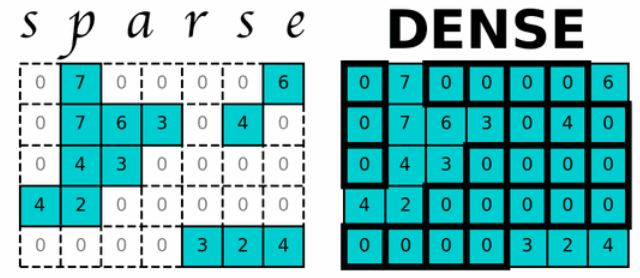
    <figcaption>sparse and dense matrix</figcaption>
</figure>


## Support Vector **Classification** (SVC)

- Three classes for classification in `sklearn.svm`
    + `SVC` ($C$-support vector classification)
    + `NuSVC` ($\nu$-support vector classification)
    + `LinearSVC` (A faster implementation of `SVC` for the case of a linear kernal)

- Can perform binary and multi-class classifcation.

- Take as input two arrays 
    + an array <font style=background:Grey color=DarkViolet>X</font> of shape <font style=background:Grey color=DarkViolet>(n_samples, n_features)</font> holding the training samples
    + an array <font style=background:Grey color=DarkViolet>y</font> of class labels (strings or integers), of shape <font style=background:Grey color=DarkViolet>(n_samples)</font>

## Mathematical formulation of `SVC`
Given training vectors $\mathbf{x}_i \in \mathbb{R}^p, i=1,\dots,n$ in two classes, and a vector $y \in \{1, -1\}^n$, our goal is to find $\mathbf{w} \in \mathbb{R}^p$ and $b \in \mathbb{R}$ such that prediction given by $\text{sign}(\mathbf{w}^\top\phi(\mathbf{x})+b)$ is correct for most samples.

`SVC` solves the following primal problem:

$$\min_{\mathbf{w}, b, \mathbf{\zeta}} \quad \frac{1}{2} \mathbf{w}^\top \mathbf{w} + C \sum_{i=1}^n \zeta_i \\
\text{s.t.} \quad y_i \left(\mathbf{w}^\top \phi(\mathbf{x}_i) + b \right) \geq 1 - \zeta_i, \\ \quad \zeta_i \geq 0, \quad i = 1, \dots, n$$

The dual problem to the primal is

$$\min_{\{\alpha_t\}} \quad \frac{1}{2} \sum_{i} \sum_{j}\alpha_i\alpha_{j} y_i y_j \phi(\mathbf{x}_i)^\top\phi(\mathbf{x}_j) - \sum_i \alpha_i \\
\text{s.t.} \quad  \sum_i \alpha_i y_i = 0, \\ \quad 0 \leq \alpha_i \leq C, \quad i = 1, \dots, n$$

The decision function for a given sample $\mathbf{x}$ becomes:

$$\text{sign}(\sum_{i \in \text{SV}}y_i\alpha_i\phi(\mathbf{x_i})^\top\phi(\mathbf{x}) + b)$$

We only need to sum over the support vectors (i.e. the samples that lie within the margin) because the dual cofficients $\alpha_i$ are zero for the other samples.

These parameters can be accessed through the attributes <font style=background:Grey color=DarkViolet>dual_coef_</font> which holds the product $y_i\alpha_i$, <font style=background:Grey color=DarkViolet>support_vectors</font> which holds the support vectors, and <font style=background:Grey color=DarkViolet>intercept_</font> which holds the independent term $b$.

In [251]:
from sklearn.svm import SVC
?SVC

Init signature:
SVC(
    *,
    C=1.0,
    kernel='rbf',
    degree=3,
    gamma='scale',
    coef0=0.0,
    shrinking=True,
    probability=False,
    tol=0.001,
    cache_size=200,
    class_weight=None,
    verbose=False,
    max_iter=-1,
    decision_function_shape='ovr',
    break_ties=False,
    random_state=None,
)
Docstring:     
C-Support Vector Classification.

The implementation is based on libsvm. The fit time scales at least
quadratically with the number of samples and may be impractical
beyond tens of thousands of samples. For large datasets
consider using :class:`~sklearn.svm.LinearSVC` or
:class:`~sklearn.linear_model.SGDClassifier` instead, possibly after a
:class:`~sklearn.kernel_approximation.Nystroem` transformer or
other :ref:`kernel_approximation`.

The multiclass support is handled according to a one-vs-one scheme.

For details on the precise mathematical formulation of the provided
kernel functions and how `gamma`, `coef0` and `degree` affect each
other, see the

## Mathematical formulation of `nuSVC`
`NuSVC` solves the following primal problem:

$$\min_{\mathbf{w}, b, \xi, \rho} \quad \frac{1}{2} \mathbf{w}^T \mathbf{w} - \nu \rho + \frac{1}{m} \sum_{i=1}^m \xi_i \\
\text{s.t.} \quad y_i \left(\mathbf{w}^T \phi(\mathbf{x}_i) + b \right) \geq \rho - \xi_i, \\
\quad \xi_i \geq 0, \quad i = 1, \dots, m, \\
\quad \rho \geq 0.$$

The dual problem to the primal is
$$\min_{\alpha} \quad \frac{1}{2} \sum_{i} \sum_{j}\alpha_i\alpha_{j} y_i y_j \phi(\mathbf{x}_i)^\top\phi(\mathbf{x}_j) \\
\text{s.t.} \quad 0 \leq \alpha_i \leq \frac{1}{l}, \quad i = 1, \dots, m, \\
\quad \sum_i \alpha_i \geq \nu, \\
\quad \sum_i \alpha_i y_i = 0.$$

The decision function for a given sample $\mathbf{x}$ becomes:

$$\text{sign}(\sum_{i \in \text{SV}}y_i\alpha_i\phi(\mathbf{x_i})^\top\phi(\mathbf{x}) + b)$$

- It is shown that $\sum_i \alpha_i \geq \nu$ can be replaced by $\sum_i \alpha_i = \nu$.
- In **LIBSVM**, we solve a scaled version because numerically $\alpha_i$ may be too small due to the constraint $\alpha_i \leq \frac{1}{l}$. That is, using $(\mathbf{\alpha}/\rho, b/\rho)$ instead of $\mathbf{(\mathbf{\alpha},b)}$.

- More details: [**LIBSVM**: A Library for Support Vector Machines](https://www.csie.ntu.edu.tw/~cjlin/papers/libsvm.pdf)

In [252]:
from sklearn.svm import NuSVC
?NuSVC

Init signature:
NuSVC(
    *,
    nu=0.5,
    kernel='rbf',
    degree=3,
    gamma='scale',
    coef0=0.0,
    shrinking=True,
    probability=False,
    tol=0.001,
    cache_size=200,
    class_weight=None,
    verbose=False,
    max_iter=-1,
    decision_function_shape='ovr',
    break_ties=False,
    random_state=None,
)
Docstring:     
Nu-Support Vector Classification.

Similar to SVC but uses a parameter to control the number of support
vectors.

The implementation is based on libsvm.

Read more in the :ref:`User Guide <svm_classification>`.

Parameters
----------
nu : float, default=0.5
    An upper bound on the fraction of margin errors (see :ref:`User Guide
    <nu_svc>`) and a lower bound of the fraction of support vectors.
    Should be in the interval (0, 1].

kernel : {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable,          default='rbf'
     Specifies the kernel type to be used in the algorithm.
     If none is given, 'rbf' will be used. If a callable is 

## How to use `SVC`, `NuSVC`, `LinearSVC`?

- A binary classification

In [ ]:
# train a SVC
from sklearn import svm
X = [[0, 0], [1, 1]]
y = [0, 1]
clf_svc = svm.SVC()
# clf_svc = svm.NuSVC()
# clf_svl = svm.LinearSVC()
clf_svc.fit(X, y)

SVC()

In [254]:
# predict using a C-SVC
print("The prediction result for [2., 2.] is %.f" % clf_svc.predict([[2., 2.]]))

The prediction result for [2., 2.] is 1


In [255]:
# get support vectors
print(clf_svc.support_vectors_)
print("----------------------------------")

# get indeices of support vectors
print(clf_svc.support_)
print("----------------------------------")

# get number of support vectors for each class
print(clf_svc.n_support_)

[[0. 0.]
 [1. 1.]]
----------------------------------
[0 1]
----------------------------------
[1 1]


# Case: SVM: maximum margin separating hyperplane

In [256]:
import matplotlib.pyplot as plt

from sklearn import svm
from sklearn.datasets import make_blobs
from sklearn.inspection import DecisionBoundaryDisplay

In [257]:
# we create 40 separable points
X, y = make_blobs(n_samples=40, centers=2, random_state=6)

# fit the model, don't regularize for illustration purposes
clf = svm.SVC(kernel="linear", C=1000)
clf.fit(X, y)

SVC(C=1000, kernel='linear')

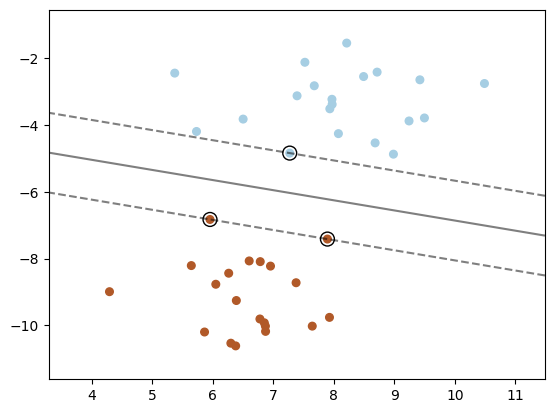

In [258]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=30, cmap=plt.cm.Paired)
# plot the decision function
ax = plt.gca()
DecisionBoundaryDisplay.from_estimator(
    clf,
    X,
    plot_method="contour",
    colors="k",
    levels=[-1, 0, 1],
    alpha=0.5,
    linestyles=["--", "-", "--"],
    ax=ax,
)
# plot support vectors
ax.scatter(
    clf.support_vectors_[:, 0],
    clf.support_vectors_[:, 1],
    s=100,
    linewidth=1,
    facecolors="none",
    edgecolors="k",
)
plt.show()

## Case: SVM-Anova: SVM with univariate feature selection

This example shows how to perform univariate feature selection before running a SVC (support vector classifier) to improve the classification scores. We use the iris dataset (4 features) and add 36 non-informative features. We can find that our model achieves best performance when we select around 10% of features.

In [259]:
# Load some data
import numpy as np
from sklearn.datasets import load_iris

X, y = load_iris(return_X_y=True)

# Add non-informative features
rng = np.random.RandomState(0)
X = np.hstack((X, 2 * rng.random((X.shape[0], 36))))

In [260]:
# create the pipeline
from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Create a feature-selection transform, a scaler and an instance of SVM that we
# combine together to have a full-blown estimator

clf = Pipeline(
    [
        ("anova", SelectPercentile(f_classif)),
        ("scaler", StandardScaler()),
        ("svc", SVC(gamma="auto")),
    ]
)

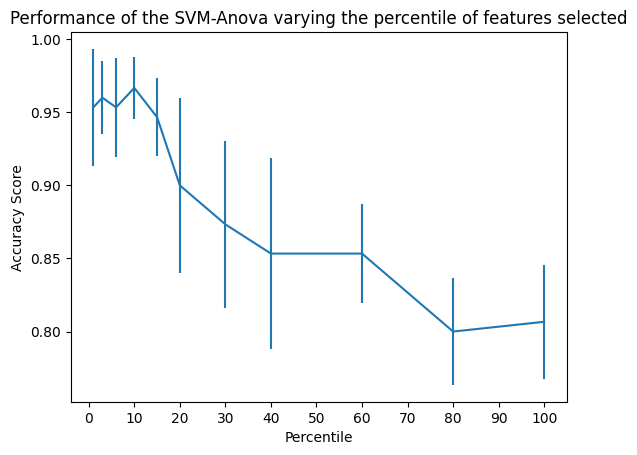

In [261]:
# Plot the cross-validation score as a function of percentile of features
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_score

score_means = list()
score_stds = list()
percentiles = (1, 3, 6, 10, 15, 20, 30, 40, 60, 80, 100)

for percentile in percentiles:
    clf.set_params(anova__percentile=percentile)
    this_scores = cross_val_score(clf, X, y)
    score_means.append(this_scores.mean())
    score_stds.append(this_scores.std())

plt.errorbar(percentiles, score_means, np.array(score_stds))
plt.title("Performance of the SVM-Anova varying the percentile of features selected")
plt.xticks(np.linspace(0, 100, 11, endpoint=True))
plt.xlabel("Percentile")
plt.ylabel("Accuracy Score")
plt.axis("tight")
plt.show()

## Multi-class classification

- `SVC` and `NuSVC` implement the ''one-versus-one'' or ''one-versus-rest'' approach for multi-class classification.
    + In total, <font style=background:Grey color=DarkViolet>n_classes * (n_calsses -1) / 2</font> classifiers are constructed and each one trains data from two classes.

- `LineaSVC` 
    + Implements ''one-versus-rest'' multi-class strategy, thus training <font style=background:Grey color=DarkViolet>n_classes</font> models.

In [262]:
# multi-class SVC
from sklearn import svm
X = [[0], [1], [2], [3]]
Y = [0, 1, 2, 3]
clf = svm.SVC(decision_function_shape='ovo')
clf.fit(X, Y)
dec = clf.decision_function([[1]])
print(dec.shape[1]) # 6 classes: 4*3/2 = 6
print("----------------------------------")

clf.decision_function_shape = "ovr"
dec = clf.decision_function([[1]])
print(dec.shape[1]) # 4 classes
print("----------------------------------")

# multi-class LinearSVC
clf_lin = svm.LinearSVC()
clf_lin.fit(X, Y)
dec = clf_lin.decision_function([[1]])
print(dec.shape[1]) # 4 classes

6
----------------------------------
4
----------------------------------
4


/Library/Python/3.9/site-packages/sklearn/svm/_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(


## Unbalanced problems

- The parameters <font style=background:Grey color=DarkViolet>class_weight</font> and <font style=background:Grey color=DarkViolet>sample_weight</font> can be used in problems where it is desired to give more importance to certain classes or certain individual samples.

- In `SVC`, it implements the parameter <font style=background:Grey color=DarkViolet>class_weight</font> in the <font style=background:Grey color=DarkViolet>fit</font> method. It is a dictionary of the form <font style=background:Grey color=DarkViolet>{class_label: value}</font>.

- In all classes of `sklearn.svm`, they implement also weights for individual samples in the <font style=background:Grey color=DarkViolet>fit</font> method through the <font style=background:Grey color=DarkViolet>sample_weight</font> parameter. Then, the parameter $C$ of the $i\text{th}$ class will be $C*\text{sample\_weight}[i]$. 


## Case: SVM: Separating hyperplane for unbalanced classes

In [263]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt

from sklearn import svm
from sklearn.datasets import make_blobs
from sklearn.inspection import DecisionBoundaryDisplay

In [264]:
# we create two clusters of random points
n_samples_1 = 1000
n_samples_2 = 100
centers = [[0.0, 0.0], [2.0, 2.0]]
clusters_std = [1.5, 0.5]
X, y = make_blobs(
    n_samples=[n_samples_1, n_samples_2],
    centers=centers,
    cluster_std=clusters_std,
    random_state=0,
    shuffle=False,
)

In [265]:
# fit the model and get the separating hyperplane
clf = svm.SVC(kernel="linear", C=1.0)
clf.fit(X, y)

SVC(kernel='linear')

In [266]:
# fit the model and get the separating hyperplane using weighted classes
wclf = svm.SVC(kernel="linear", class_weight={1: 10})
wclf.fit(X, y)

SVC(class_weight={1: 10}, kernel='linear')

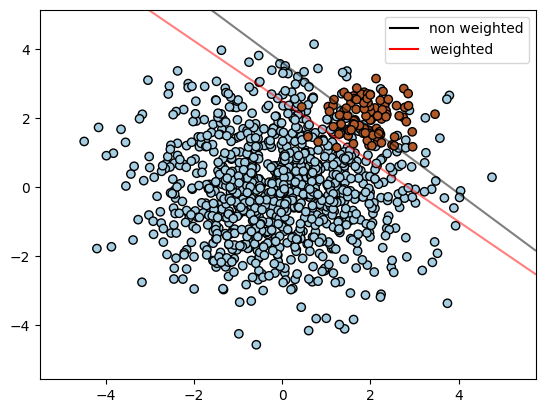

In [267]:
# plot the samples
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Paired, edgecolors="k")
# plot the decision functions for both classifiers
ax = plt.gca()
disp = DecisionBoundaryDisplay.from_estimator(
    clf,
    X,
    plot_method="contour",
    colors="k",
    levels=[0],
    alpha=0.5,
    linestyles=["-"],
    ax=ax,
)
# plot decision boundary and margins for weighted classes
wdisp = DecisionBoundaryDisplay.from_estimator(
    wclf,
    X,
    plot_method="contour",
    colors="r",
    levels=[0],
    alpha=0.5,
    linestyles=["-"],
    ax=ax,
)
plt.legend(
    [
        mlines.Line2D([], [], color="k", label="non weighted"),
        mlines.Line2D([], [], color="r", label="weighted"),
    ],
    ["non weighted", "weighted"],
    loc="upper right",
)
plt.show()

## Case: Weighted samples

In [268]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn import svm

In [269]:
def plot_decision_function(classifier, sample_weight, axis, title):
    # plot the decision function
    xx, yy = np.meshgrid(np.linspace(-4, 5, 500), np.linspace(-4, 5, 500))

    Z = classifier.decision_function(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # plot the line, the points, and the nearest vectors to the plane
    axis.contourf(xx, yy, Z, alpha=0.75, cmap=plt.cm.bone)
    axis.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        s=100 * sample_weight,
        alpha=0.9,
        cmap=plt.cm.bone,
        edgecolors="black",
    )

    axis.axis("off")
    axis.set_title(title)

In [270]:
# we create 20 points
np.random.seed(0)
X = np.r_[np.random.randn(10, 2) + [1, 1], np.random.randn(10, 2)]
y = [1] * 10 + [-1] * 10
sample_weight_last_ten = abs(np.random.randn(len(X)))
sample_weight_constant = np.ones(len(X))
# and bigger weights to some outliers
sample_weight_last_ten[15:] *= 5
sample_weight_last_ten[9] *= 15

# Fit the models.

# This model does not take into account sample weights.
clf_no_weights = svm.SVC(gamma=1)
clf_no_weights.fit(X, y)

SVC(gamma=1)

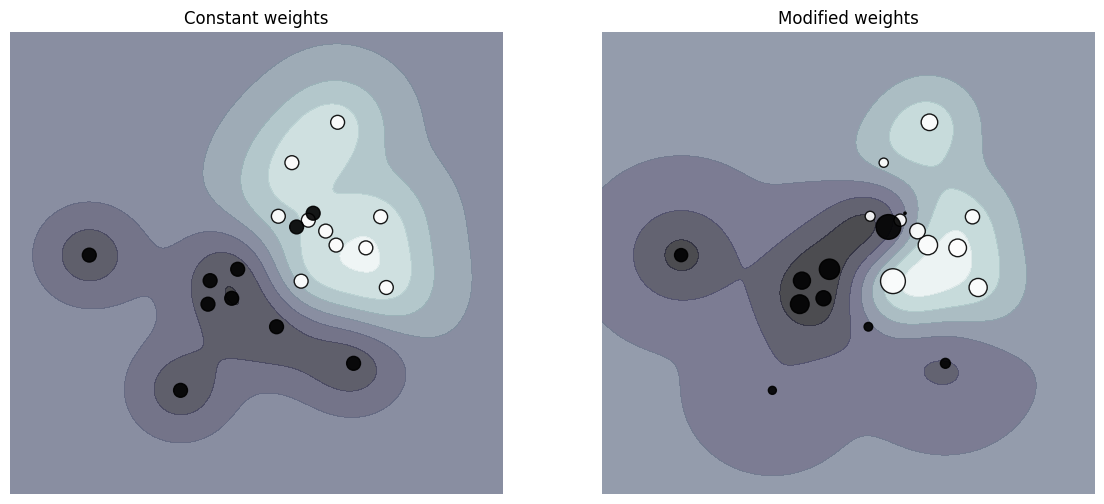

In [271]:
# This other model takes into account some dedicated sample weights.
clf_weights = svm.SVC(gamma=1)
clf_weights.fit(X, y, sample_weight=sample_weight_last_ten)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_decision_function(
    clf_no_weights, sample_weight_constant, axes[0], "Constant weights"
)
plot_decision_function(clf_weights, sample_weight_last_ten, axes[1], "Modified weights")
plt.show()

## Support Vector **Regression** (SVR)

- Three classes for regression in `sklearn.svm`
    + `SVR` ($\epsilon$-support vector regression)
    + `NuSVR` ($\nu$-support vector regression)
    + `LinearSVR` (A faster implementation of `SVR` for the case of a linear kernal)

## Mathematical formulation of `SVR`
Consider a set of training points, $\{(\mathbf{x}_1, z_1), \dots, (\mathbf{x}_l,z_l)\}$, where $\mathbf{x}_i \in \mathbb{R}^n$ is a feature vector and $z_i \in \mathbb{R}$ is the traget output. Under given parameters $C>0$ and $\epsilon>0$.

`SVR` solves the following primal problem ([Vapnik, 1998](http://lib.ysu.am/disciplines_bk/22cca8eefb24af29d10bbc661e3a5ebf.pdf)):

$$\min_{\mathbf{w}, b, \mathbf{\xi}, \mathbf{\xi}^*} \quad \frac{1}{2} \mathbf{w}^T \mathbf{w} + C \sum_{i=1}^l \xi_i + C \sum_{i=1}^l \xi_i^* \\
\text{s.t.} \quad 
\mathbf{w}^T \mathbf{\phi}(\mathbf{x}_i) + b - z_i \leq \epsilon + \xi_i, \\
z_i - \mathbf{w}^T \mathbf{\phi}(\mathbf{x}_i) - b \leq \epsilon + \xi_i^*, \\
\xi_i, \xi_i^* \geq 0, \quad i = 1, \dots, l.$$


The dual problem to the primal is

$$\min_{\mathbf{\alpha}, \mathbf{\alpha}^*} \quad 
\frac{1}{2} (\mathbf{\alpha} - \mathbf{\alpha}^*)^T \mathbf{Q} (\mathbf{\alpha} - \mathbf{\alpha}^*) 
+ \epsilon \sum_{i=1}^l (\alpha_i + \alpha_i^*) 
+ \sum_{i=1}^l z_i (\alpha_i - \alpha_i^*) \\
\text{s.t.} \quad 
\mathbf{e}^T (\mathbf{\alpha} - \mathbf{\alpha}^*) = 0, \\
0 \leq \alpha_i, \alpha_i^* \leq C, \quad i = 1, \dots, l.$$
where $Q_{ij}=K(\mathbf{x}_i,\mathbf{x}_j)=\mathbf{\phi}(\mathbf{x}_i)\mathbf{\phi}(\mathbf{x}_j)$.

After solving the problem, the approximate function for a sample $\mathbf{x}$ is

$$\sum_{i=1}^l(-\alpha_i+\alpha_i^*)K(\mathbf{x}_i,\mathbf{x}) + b$$

In [272]:
from sklearn.svm import SVR
?SVR

Init signature:
SVR(
    *,
    kernel='rbf',
    degree=3,
    gamma='scale',
    coef0=0.0,
    tol=0.001,
    C=1.0,
    epsilon=0.1,
    shrinking=True,
    cache_size=200,
    verbose=False,
    max_iter=-1,
)
Docstring:     
Epsilon-Support Vector Regression.

The free parameters in the model are C and epsilon.

The implementation is based on libsvm. The fit time complexity
is more than quadratic with the number of samples which makes it hard
to scale to datasets with more than a couple of 10000 samples. For large
datasets consider using :class:`~sklearn.svm.LinearSVR` or
:class:`~sklearn.linear_model.SGDRegressor` instead, possibly after a
:class:`~sklearn.kernel_approximation.Nystroem` transformer or
other :ref:`kernel_approximation`.

Read more in the :ref:`User Guide <svm_regression>`.

Parameters
----------
kernel : {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable,          default='rbf'
     Specifies the kernel type to be used in the algorithm.
     If none 

## Mathematical formulation of `NuSVR`
Consider a set of training points, $\{(\mathbf{x}_1, z_1), \dots, (\mathbf{x}_l,z_l)\}$, where $\mathbf{x}_i \in \mathbb{R}^n$ is a feature vector and $z_i \in \mathbb{R}$ is the traget output. Under given parameters $C>0$ and $\epsilon>0$.

`NuSVR` solves the following primal problem:

$$\min_{\mathbf{w}, b, \mathbf{\xi}, \mathbf{\xi}^*, \epsilon} \quad 
\frac{1}{2} \mathbf{w}^\top \mathbf{w} + C \left( \nu \epsilon + \frac{1}{l} \sum_{i=1}^l (\xi_i + \xi_i^*) \right) \\
\text{s.t.} \quad 
(\mathbf{w}^\top \mathbf{\phi}(\mathbf{x}_i) + b) - z_i \leq \epsilon + \xi_i, \\
z_i - (\mathbf{w}^\top \mathbf{\phi}(\mathbf{x}_i) + b) \leq \epsilon + \xi_i^*, \\
\xi_i, \xi_i^* \geq 0, \quad i = 1, \dots, l, \\
\epsilon \geq 0.$$


The dual problem to the primal is

$$\min_{\mathbf{\alpha}, \mathbf{\alpha}^*} \quad \frac{1}{2} (\mathbf{\alpha} - \mathbf{\alpha}^*)^\top \mathbf{Q} (\mathbf{\alpha} - \mathbf{\alpha}^*) + \mathbf{z}^\top (\mathbf{\alpha} - \mathbf{\alpha}^*) \\
\text{s.t,} \quad \mathbf{e}^\top (\mathbf{\alpha} - \mathbf{\alpha}^*) = 0, \\
\quad \mathbf{e}^\top (\mathbf{\alpha} + \mathbf{\alpha}^*) \leq Cv, \\
\quad 0 \leq \alpha_i, \alpha_i^* \leq \frac{C}{l}, \quad i = 1, \ldots, l.$$

The approximate function of a sample $\mathbf{x}$ is

$$\sum_{i=1}^l (-\alpha_i + \alpha_i^*) K(\mathbf{x}_i, \mathbf{x}) + b$$

In [273]:
from sklearn.svm import NuSVR
?NuSVR

Init signature:
NuSVR(
    *,
    nu=0.5,
    C=1.0,
    kernel='rbf',
    degree=3,
    gamma='scale',
    coef0=0.0,
    shrinking=True,
    tol=0.001,
    cache_size=200,
    verbose=False,
    max_iter=-1,
)
Docstring:     
Nu Support Vector Regression.

Similar to NuSVC, for regression, uses a parameter nu to control
the number of support vectors. However, unlike NuSVC, where nu
replaces C, here nu replaces the parameter epsilon of epsilon-SVR.

The implementation is based on libsvm.

Read more in the :ref:`User Guide <svm_regression>`.

Parameters
----------
nu : float, default=0.5
    An upper bound on the fraction of training errors and a lower bound of
    the fraction of support vectors. Should be in the interval (0, 1].  By
    default 0.5 will be taken.

C : float, default=1.0
    Penalty parameter C of the error term.

kernel : {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable,          default='rbf'
     Specifies the kernel type to be used in the algorithm.

## How to use `SVR`, `NuSVR`, `LinearSVR`?

In [ ]:
from sklearn import svm
X = [[0, 0], [2, 2]]
y = [0.5, 2.5]
regr = svm.SVR()
# regr = svm.NuSVR()
# regr = svm.LinearSVR()
regr.fit(X, y)

SVR()

In [275]:
regr.predict([[1, 1]])

array([1.5])

## Density estimation, novelty detection

- `OneClassSVM` (implements a One-Class SVM which is used in outlier detection)
  - classifying new data as similar or different to the training set

## Mathematical formulation of `OneClassSVM`
`OneClassSVM` solves the following primal problem:

$$\min_{\mathbf{w}, \mathbf{\xi}, \rho} \quad \frac{1}{2} \mathbf{w}^T \mathbf{w} - \rho + \frac{1}{\nu l} \sum_{i=1}^{l} \xi_i \\
    \text{s.t.} \quad \mathbf{w}^T \mathbf{\phi}(\mathbf{x}_i) \geq \rho - \xi_i, \\
    \xi_i \geq 0, \, i = 1, \ldots, l.$$

The dual problem to the primal is

$$\min_{\mathbf{\alpha}} \quad \frac{1}{2} \mathbf{\alpha}^T \mathbf{Q} \mathbf{\alpha} \\
    \text{s.t.} \quad 0 \leq \alpha_i \leq 1/(\nu l), \, i = 1, \ldots, l, \\
    \mathbf{e}^T \mathbf{\alpha} = 1$$
where $Q_{ij}=K(\mathbf{x}_i, \mathbf{x}_j)=\mathbf{\phi}(\mathbf{x}_i)^\top\mathbf{\phi}(\mathbf{x}_j)$


The approximate function of a sample $\mathbf{x}$ is

$$\text{sign}\left(\sum_{i=1}^l\alpha_i K(\mathbf{x}_i,\mathbf{x}) - \rho\right)$$

In [276]:
from sklearn.svm import OneClassSVM
?OneClassSVM

Init signature:
OneClassSVM(
    *,
    kernel='rbf',
    degree=3,
    gamma='scale',
    coef0=0.0,
    tol=0.001,
    nu=0.5,
    shrinking=True,
    cache_size=200,
    verbose=False,
    max_iter=-1,
)
Docstring:     
Unsupervised Outlier Detection.

Estimate the support of a high-dimensional distribution.

The implementation is based on libsvm.

Read more in the :ref:`User Guide <outlier_detection>`.

Parameters
----------
kernel : {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable,          default='rbf'
     Specifies the kernel type to be used in the algorithm.
     If none is given, 'rbf' will be used. If a callable is given it is
     used to precompute the kernel matrix.

degree : int, default=3
    Degree of the polynomial kernel function ('poly').
    Must be non-negative. Ignored by all other kernels.

gamma : {'scale', 'auto'} or float, default='scale'
    Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.

    - if ``gamma='scale'`` (default) is passed th

## Case: Comparing anomaly detection algorithms for outlier detection on toy datasets
https://scikit-learn.org/stable/auto_examples/miscellaneous/plot_anomaly_comparison.html

In [355]:
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np

from sklearn import svm
from sklearn.covariance import EllipticEnvelope
from sklearn.datasets import make_blobs, make_moons
from sklearn.ensemble import IsolationForest
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDOneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import make_pipeline

In [356]:
matplotlib.rcParams["contour.negative_linestyle"] = "solid"

# Example settings
n_samples = 300
outliers_fraction = 0.15
n_outliers = int(outliers_fraction * n_samples)
n_inliers = n_samples - n_outliers

In [357]:
# define outlier/anomaly detection methods to be compared.
# the SGDOneClassSVM must be used in a pipeline with a kernel approximation
# to give similar results to the OneClassSVM
anomaly_algorithms = [
    (
        "Robust covariance",
        EllipticEnvelope(contamination=outliers_fraction, random_state=42),
    ),
    ("One-Class SVM", svm.OneClassSVM(nu=outliers_fraction, kernel="rbf", gamma=0.1)),
    (
        "One-Class SVM (SGD)",
        make_pipeline(
            Nystroem(gamma=0.1, random_state=42, n_components=150),
            SGDOneClassSVM(
                nu=outliers_fraction,
                shuffle=True,
                fit_intercept=True,
                random_state=42,
                tol=1e-6,
            ),
        ),
    ),
    (
        "Isolation Forest",
        IsolationForest(contamination=outliers_fraction, random_state=42),
    ),
    (
        "Local Outlier Factor",
        LocalOutlierFactor(n_neighbors=35, contamination=outliers_fraction),
    ),
]

In [358]:
# Define datasets
blobs_params = dict(random_state=0, n_samples=n_inliers, n_features=2)
datasets = [
    make_blobs(centers=[[0, 0], [0, 0]], cluster_std=0.5, **blobs_params)[0],
    make_blobs(centers=[[2, 2], [-2, -2]], cluster_std=[0.5, 0.5], **blobs_params)[0],
    make_blobs(centers=[[2, 2], [-2, -2]], cluster_std=[1.5, 0.3], **blobs_params)[0],
    4.0
    * (
        make_moons(n_samples=n_samples, noise=0.05, random_state=0)[0]
        - np.array([0.5, 0.25])
    ),
    14.0 * (np.random.RandomState(42).rand(n_samples, 2) - 0.5),
]

In [359]:
# Compare given classifiers under given settings
xx, yy = np.meshgrid(np.linspace(-7, 7, 150), np.linspace(-7, 7, 150))

plt.figure(figsize=(len(anomaly_algorithms) * 2 + 4, 12.5))
plt.subplots_adjust(
    left=0.02, right=0.98, bottom=0.001, top=0.96, wspace=0.05, hspace=0.01
)

plot_num = 1
rng = np.random.RandomState(42)

<Figure size 1400x1250 with 0 Axes>

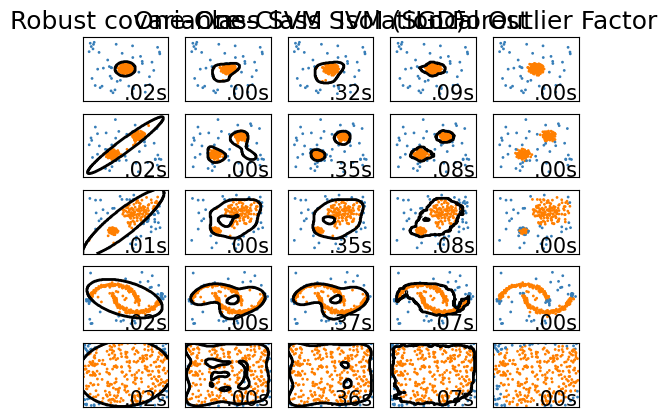

In [360]:
for i_dataset, X in enumerate(datasets):
    # Add outliers
    X = np.concatenate([X, rng.uniform(low=-6, high=6, size=(n_outliers, 2))], axis=0)

    for name, algorithm in anomaly_algorithms:
        t0 = time.time()
        algorithm.fit(X)
        t1 = time.time()
        plt.subplot(len(datasets), len(anomaly_algorithms), plot_num)
        if i_dataset == 0:
            plt.title(name, size=18)

        # fit the data and tag outliers
        if name == "Local Outlier Factor":
            y_pred = algorithm.fit_predict(X)
        else:
            y_pred = algorithm.fit(X).predict(X)

        # plot the levels lines and the points
        if name != "Local Outlier Factor":  # LOF does not implement predict
            Z = algorithm.predict(np.c_[xx.ravel(), yy.ravel()])
            Z = Z.reshape(xx.shape)
            plt.contour(xx, yy, Z, levels=[0], linewidths=2, colors="black")

        colors = np.array(["#377eb8", "#ff7f00"])
        plt.scatter(X[:, 0], X[:, 1], s=1, color=colors[(y_pred + 1) // 2])

        plt.xlim(-7, 7)
        plt.ylim(-7, 7)
        plt.xticks(())
        plt.yticks(())
        plt.text(
            0.99,
            0.01,
            ("%.2fs" % (t1 - t0)).lstrip("0"),
            transform=plt.gca().transAxes,
            size=15,
            horizontalalignment="right",
        )
        plot_num += 1
# plt.show()

## Kernel functions

- Some common kernel functions:
    + linear: $\langle\mathbf{x}, \mathbf{x}^\prime\rangle$
    + polynomial: $(\gamma\langle\mathbf{x}, \mathbf{x}^\prime\rangle + r)^d$, where $d$ is specified by parameter <font style=background:Grey color=DarkViolet>degree</font>, $\mathbf{r}$ by <font style=background:Grey color=DarkViolet>coef0</font>.
    + rbf: $\exp(-\gamma||\mathbf{x}-\mathbf{x}^\prime||^2)$, where $\gamma$ is specified by parameter <font style=background:Grey color=DarkViolet>gamma</font>, must be greater than $0$.
    + sigmoid: $\text{tanh}(\gamma\langle\mathbf{x},\mathbf{x}^\prime\rangle + r)$, where $r$ is specified by <font style=background:Grey color=DarkViolet>coef0</font>.

In [283]:
from sklearn import svm
linear_svc = svm.SVC(kernel='linear')
linear_svc.kernel

'linear'

In [284]:
rbf_svc = svm.SVC(kernel='rbf')
rbf_svc.kernel

'rbf'

## Case: RBF SVM parameters

- binary classification with only 2 input feature

In [285]:
import numpy as np
from matplotlib.colors import Normalize

class MidpointNormalize(Normalize):
    def __init__(self, vmin=None, vmax=None, midpoint=None, clip=False):
        self.midpoint = midpoint
        Normalize.__init__(self, vmin, vmax, clip)

    def __call__(self, value, clip=None):
        x, y = [self.vmin, self.midpoint, self.vmax], [0, 0.5, 1]
        return np.ma.masked_array(np.interp(value, x, y))

In [286]:
# Load and prepare dataset
#dataset for grid search
from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data
y = iris.target

In [287]:
#Dataset for decision function visualization:
#we only keep the first two features in X and sub-sample the dataset to keep only 2 classes and make it a binary classification problem.
X_2d = X[:, :2]
X_2d = X_2d[y > 0]
y_2d = y[y > 0]
y_2d -= 1

In [288]:
#scale the data
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(X)
X_2d = scaler.fit_transform(X_2d)

In [289]:
# Train classifiers
from sklearn.model_selection import GridSearchCV, StratifiedShuffleSplit
from sklearn.svm import SVC

C_range = np.logspace(-2, 10, 13)
gamma_range = np.logspace(-9, 3, 13)
param_grid = dict(gamma=gamma_range, C=C_range)
cv = StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=42)
grid = GridSearchCV(SVC(), param_grid=param_grid, cv=cv)
grid.fit(X, y)

print(
    "The best parameters are %s with a score of %0.2f"
    % (grid.best_params_, grid.best_score_)
)

The best parameters are {'C': 1.0, 'gamma': 0.1} with a score of 0.97


In [290]:
# fit a classifier for all parameters in the 2d version
C_2d_range = [1e-2, 1, 1e2]
gamma_2d_range = [1e-1, 1, 1e1]
classifiers = []
for C in C_2d_range:
    for gamma in gamma_2d_range:
        clf = SVC(C=C, gamma=gamma)
        clf.fit(X_2d, y_2d)
        classifiers.append((C, gamma, clf))

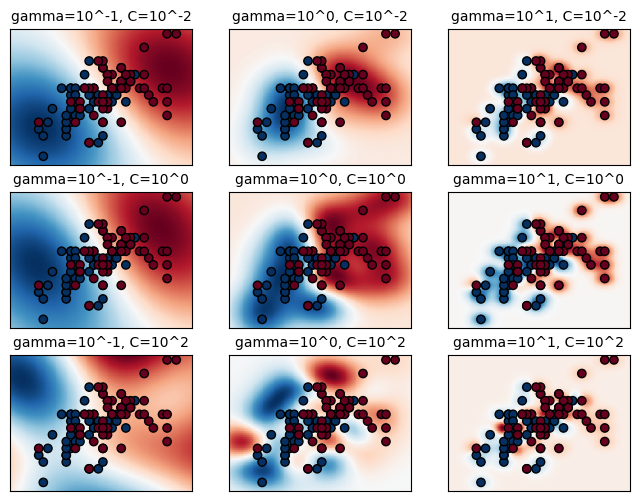

In [291]:
# draw visualization of parameter effects
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
xx, yy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
for k, (C, gamma, clf) in enumerate(classifiers):
    # evaluate decision function in a grid
    Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # visualize decision function for these parameters
    plt.subplot(len(C_2d_range), len(gamma_2d_range), k + 1)
    plt.title("gamma=10^%d, C=10^%d" % (np.log10(gamma), np.log10(C)), size="medium")

    # visualize parameter's effect on decision function
    plt.pcolormesh(xx, yy, -Z, cmap=plt.cm.RdBu)
    plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y_2d, cmap=plt.cm.RdBu_r, edgecolors="k")
    plt.xticks(())
    plt.yticks(())
    plt.axis("tight")

scores = grid.cv_results_["mean_test_score"].reshape(len(C_range), len(gamma_range))

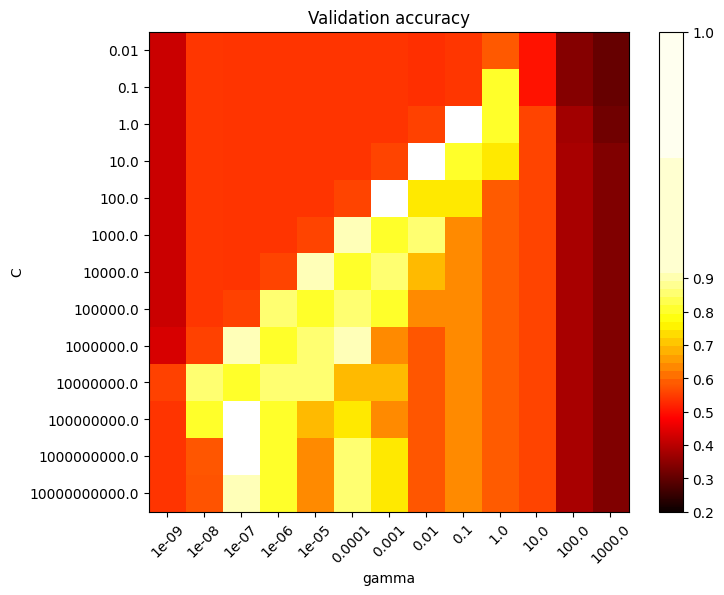

In [292]:
# Draw heatmap of the validation accuracy as a function of gamma and C
plt.figure(figsize=(8, 6))
plt.subplots_adjust(left=0.2, right=0.95, bottom=0.15, top=0.95)
plt.imshow(
    scores,
    interpolation="nearest",
    cmap=plt.cm.hot,
    norm=MidpointNormalize(vmin=0.2, midpoint=0.92),
)
plt.xlabel("gamma")
plt.ylabel("C")
plt.colorbar()
plt.xticks(np.arange(len(gamma_range)), gamma_range, rotation=45)
plt.yticks(np.arange(len(C_range)), C_range)
plt.title("Validation accuracy")
plt.show()

## Custom kernels

- Define your own kernels by
    + Using Python functions as custom kernels
    + Using the Gram matrix
<br />

- Classifiers with custom kernels behave the same way as any other classifiers, except that:
    + <font style=background:Grey color=DarkViolet>support_vectors_</font> is empty, only indices of support vectors are stored in <font style=background:Grey color=DarkViolet>support_</font>
    + A reference (and not a copy) of the first argument in the <font style=background:Grey color=DarkViolet>fit()</font> method is stored for future reference. If that array changes between the use of <font style=background:Grey color=DarkViolet>fit()</font> and <font style=background:Grey color=DarkViolet>predict()</font> you will have unexpected results.


## Using Python functions as custom kernels

- Passing a function to the `kernel` parameter.

- The parameter of functions: two matrix of shape (n_sample_1, n_features), (n_samples_2, n_features).

- The return value of functions: a kernel matrix of shape (n_samples_1, n_samples_2).

In [293]:
import numpy as np
from sklearn import svm
def my_kernel(X, Y):
    return np.dot(X, Y.T)
clf = svm.SVC(kernel=my_kernel)

## Using the Gram matrix

- Pass pre-computed kernels by using the kernel='precomputed' option.

- pass Gram matrix instead of $\mathbf{X}$ to the `fit` and `predict`.

- The kernel values between all training vectors and test vectors must be provided.

In [294]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn import svm
X, y = make_classification(n_samples=10, random_state=0)
X_train , X_test , y_train, y_test = train_test_split(X, y, random_state=0)
clf = svm.SVC(kernel='precomputed')
# linear kernel computation
gram_train = np.dot(X_train, X_train.T)
clf.fit(gram_train, y_train)

SVC(kernel='precomputed')

In [295]:
# predict on training examples
gram_test = np.dot(X_test, X_train.T)
clf.predict(gram_test)

array([0, 1, 0])

## Case: SVM with custom kernel

In [296]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn import datasets, svm
from sklearn.inspection import DecisionBoundaryDisplay

In [297]:
# import some data to play with
iris = datasets.load_iris()
X = iris.data[:, :2]  # we only take the first two features. We could
# avoid this ugly slicing by using a two-dim dataset
Y = iris.target

In [298]:
def my_kernel(X, Y):
    """
    We create a custom kernel:

                 (2  0)
    k(X, Y) = X  (    ) Y.T
                 (0  1)
    """
    M = np.array([[2, 0], [0, 1.0]])
    return np.dot(np.dot(X, M), Y.T)

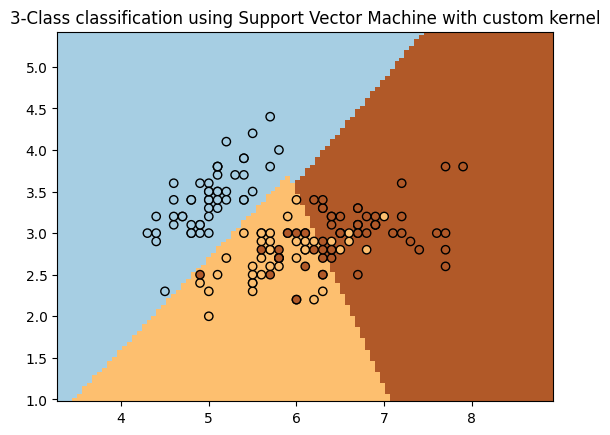

In [299]:
h = 0.02  # step size in the mesh

# we create an instance of SVM and fit out data.
clf = svm.SVC(kernel=my_kernel)
clf.fit(X, Y)

ax = plt.gca()
DecisionBoundaryDisplay.from_estimator(
    clf,
    X,
    cmap=plt.cm.Paired,
    ax=ax,
    response_method="predict",
    plot_method="pcolormesh",
    shading="auto",
)

# Plot also the training points
plt.scatter(X[:, 0], X[:, 1], c=Y, cmap=plt.cm.Paired, edgecolors="k")
plt.title("3-Class classification using Support Vector Machine with custom kernel")
plt.axis("tight")
plt.show()

## Kernel approximation
- Some feature functions perform non-linear transformations of the input, which can serve as a basis for linear classification or other algorithms.

- Compared to the Kernel trick, approximate explicit feature maps
    + can be better suited for online learning.
    + can significantly reduce the cost of learning with very large datasets.

- Some methods for kernel approximation
    + Nystroem method
    + Radial basis function kernel
    + Additive Chi-squared kernel
    + Skewed Chi-squared kernel
    + Polynomial kernel approximation via tensor sketch

- More details: [Kernel Approximation](https://scikit-learn.org/stable/modules/kernel_approximation.html#kernel-approximation)
    

## Case: radial basis function kernel
https://scikit-learn.cn/stable/auto_examples/miscellaneous/plot_kernel_approximation.html#sphx-glr-auto-examples-miscellaneous-plot-kernel-approximation-py

In [361]:
from sklearn.kernel_approximation import RBFSampler
from sklearn.linear_model import SGDClassifier
X = [[0, 0], [1, 1], [1, 0], [0, 1]]
y = [0, 0, 1, 1]
rbf_feature = RBFSampler(gamma=1, random_state=1)
X_features = rbf_feature.fit_transform(X)
clf = SGDClassifier(max_iter=5)
clf.fit(X_features, y)
clf.score(X_features, y)

/Library/Python/3.9/site-packages/sklearn/linear_model/_stochastic_gradient.py:713: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


1.0

# Summary for `svm`

- Data requirment

- classification (`SVC`, `NuSVC`, `LinearSVC`)

- Regression (`SVR`, `NuSVR`, `LinearSVR`)

- Density estimation, novelty detection (`OneClassSVM`)

- Kernel (common kernels, custom kernels, kernel approximation)